# 2.4 Model Selection: Choosing the Champion

**Purpose:** Compare four candidate models (mean baseline, Linear Regression, Ridge, Lasso) on identical train and test data, and make an evidence-based final recommendation.

**Method:**
- Same cleaned data, same features (surface area, lat, lon, neighborhood), same split (`test_size=0.2`, `random_state=42`)
- Same preprocessing in every pipeline: `OneHotEncoder` (category_encoders) -> `StandardScaler`
- Ridge and Lasso tuned by cross-validation (`RidgeCV`, `LassoCV`), not by looking at test error
- Metric: RMSE, with the train-test gap used to check for overfitting

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from category_encoders import OneHotEncoder

from wrangle import clean_files

In [2]:
df = clean_files("../data/raw/buenos-aires-real-estate-*.csv")

target = "price_aprox_usd"
feature = [col for col in df.columns if col != target]

X = df[feature]
y = df[target]

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(feature)

X_train_4, X_test_4, y_train_4, y_test_4 = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training rows: {len(X_train_4)}")
print(f"Testing rows: {len(X_test_4)}")

Features shape: (6247, 4)
Target shape: (6247,)
['surface_covered_in_m2', 'lat', 'lon', 'neighborhood']
Training rows: 4997
Testing rows: 1250


## 1. Fair comparison setup

All four models share the same cleaned data, features, split (`random_state=42`, `test_size=0.2`), preprocessing chain and metric (RMSE), so any difference in results comes from the models and not from the data.

## 2. Reusable metrics function

Instead of repeating the RMSE formula eight times (4 models x train/test), one function computes it for any fitted model and any split.

In [3]:
def get_rmse_4(model, X, y_true):
    """
    Calculate RMSE for a fitted sklearn model or pipeline on a given dataset.
    """
    y_pred = model.predict(X)
    rmse = root_mean_squared_error(y_true, y_pred)
    return rmse

print("Function created successfully!")

Function created successfully!


## 3. Training the candidate models

### 3.1 Baseline (mean predictor)

Predicts the training-set mean price for every apartment. This is the floor any real model has to beat.

In [4]:
y_mean_4 = y_train_4.mean()

y_pred_baseline_train = [y_mean_4] * len(y_train_4)
y_pred_baseline_test = [y_mean_4] * len(y_test_4)

rmse_base_train = root_mean_squared_error(y_train_4, y_pred_baseline_train)
rmse_base_test = root_mean_squared_error(y_test_4, y_pred_baseline_test)

print(f"Mean price (train): ${y_mean_4:,.2f}")
print(f"Baseline Train RMSE: ${rmse_base_train:,.2f}")
print(f"Baseline Test RMSE: ${rmse_base_test:,.2f}")

Mean price (train): $133,867.26
Baseline Train RMSE: $58,828.12
Baseline Test RMSE: $61,059.08


### 3.2 Linear Regression (no regularization)

Ordinary least squares on all features, with the same `OneHotEncoder` -> `StandardScaler` preprocessing as the regularized models. This is the reference point: what do we get with no penalty at all?

In [5]:
model_linear_4 = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    LinearRegression()
)

model_linear_4.fit(X_train_4, y_train_4)

rmse_linear_train = get_rmse_4(model_linear_4, X_train_4, y_train_4)
rmse_linear_test = get_rmse_4(model_linear_4, X_test_4, y_test_4)

print(f"Linear Regression Train RMSE: ${rmse_linear_train:,.2f}")
print(f"Linear Regression Test RMSE: ${rmse_linear_test:,.2f}")

Linear Regression Train RMSE: $33,174.63
Linear Regression Test RMSE: $36,971.86


### 3.3 Ridge Regression (RidgeCV)

Ridge adds an L2 penalty that shrinks all coefficients without zeroing any. `RidgeCV` selects alpha automatically from 100 candidate values between 0.01 and 10,000, using only the training data.

In [6]:
model_ridge_4 = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    RidgeCV(alphas=np.logspace(-2, 4, 100))
)

model_ridge_4.fit(X_train_4, y_train_4)

rmse_ridge_train = get_rmse_4(model_ridge_4, X_train_4, y_train_4)
rmse_ridge_test = get_rmse_4(model_ridge_4, X_test_4, y_test_4)

alpha_ridge_chosen = model_ridge_4.named_steps["ridgecv"].alpha_
print(f"Best Ridge alpha: {alpha_ridge_chosen:.6f}")
print(f"Ridge Train RMSE: ${rmse_ridge_train:,.2f}")
print(f"Ridge Test RMSE: ${rmse_ridge_test:,.2f}")

Best Ridge alpha: 49.770236
Ridge Train RMSE: $33,179.65
Ridge Test RMSE: $36,948.50


### 3.4 Lasso Regression (LassoCV)

Lasso adds an L1 penalty that can set coefficients exactly to zero (automatic feature selection). `LassoCV` selects alpha by 5-fold cross-validation on the training data. `max_iter=100000` is used because the default 10,000 iterations triggered convergence warnings at small alphas in lesson 2.3.

In [7]:
model_lasso_4 = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    LassoCV(alphas=np.logspace(-4, 2, 100), max_iter=100000)
)

model_lasso_4.fit(X_train_4, y_train_4)

rmse_lasso_train = get_rmse_4(model_lasso_4, X_train_4, y_train_4)
rmse_lasso_test = get_rmse_4(model_lasso_4, X_test_4, y_test_4)

alpha_lasso_chosen = model_lasso_4.named_steps["lassocv"].alpha_
print(f"Best Lasso alpha: {alpha_lasso_chosen:.6f}")
print(f"Lasso Train RMSE: ${rmse_lasso_train:,.2f}")
print(f"Lasso Test RMSE: ${rmse_lasso_test:,.2f}")

Best Lasso alpha: 100.000000
Lasso Train RMSE: $33,195.81
Lasso Test RMSE: $36,916.38


#### Sanity check: is Lasso's alpha at the edge of the grid?

`LassoCV` picked alpha = 100, which is the largest value in the lesson's grid (`np.logspace(-4, 2, 100)`). When the best value sits on the boundary, the true optimum might lie beyond it. To check, the grid is extended to alpha = 1,000 in a separate model. Only cross-validation error on the training data is used for this check, not test error.

In [8]:
lasso_wide_4 = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    LassoCV(alphas=np.logspace(-4, 3, 140), max_iter=100000)
)
lasso_wide_4.fit(X_train_4, y_train_4)

cv_wide = lasso_wide_4.named_steps["lassocv"]
cv_rmse_wide = np.sqrt(cv_wide.mse_path_.mean(axis=1))

print(f"Best alpha on wider grid: {cv_wide.alpha_:.4f}")
print(f"Non-zero coefficients: {(cv_wide.coef_ != 0).sum()}")
print(f"Best CV RMSE: ${cv_rmse_wide.min():,.2f}")

# CV RMSE near alpha = 100 vs. the best
i_100 = np.argmin(np.abs(cv_wide.alphas_ - 100))
print(f"CV RMSE at alpha ~ {cv_wide.alphas_[i_100]:.1f}: ${cv_rmse_wide[i_100]:,.2f}")

Best alpha on wider grid: 124.0296
Non-zero coefficients: 49
Best CV RMSE: $33,575.80
CV RMSE at alpha ~ 98.4: $33,577.12


## 4. Unified comparison table

All four models side by side. **Test RMSE** is the honest measure of performance on unseen data. **Gap** (Test - Train) shows how much worse each model does on new data than on the data it learned from. The baseline's gap reflects only a slightly more spread-out test split, since it learns nothing.

In [9]:
data_4 = {
    "Model": ["Baseline", "Linear Regression", "Ridge (CV-tuned)", "Lasso (CV-tuned)"],
    "Train_RMSE": [rmse_base_train, rmse_linear_train, rmse_ridge_train, rmse_lasso_train],
    "Test_RMSE": [rmse_base_test, rmse_linear_test, rmse_ridge_test, rmse_lasso_test],
}

df_results_4 = pd.DataFrame(data_4)
df_results_4["Gap"] = df_results_4["Test_RMSE"] - df_results_4["Train_RMSE"]
df_results_4["Gap_pct"] = df_results_4["Gap"] / df_results_4["Train_RMSE"] * 100
df_results_4 = df_results_4.set_index("Model")

print("\n" + "=" * 60)
print("MODEL COMPARISON TABLE")
print("=" * 60)
print(df_results_4.round(2))
print("=" * 60)


MODEL COMPARISON TABLE
                   Train_RMSE  Test_RMSE      Gap  Gap_pct
Model                                                     
Baseline             58828.12   61059.08  2230.96     3.79
Linear Regression    33174.63   36971.86  3797.23    11.45
Ridge (CV-tuned)     33179.65   36948.50  3768.85    11.36
Lasso (CV-tuned)     33195.81   36916.38  3720.57    11.21


### Results: comparison table

| Model | Train RMSE | Test RMSE | Gap | Gap % |
|---|---|---|---|---|
| Baseline | $58,828 | $61,059 | $2,231 | 3.8% |
| Linear Regression | $33,175 | $36,972 | $3,797 | 11.5% |
| Ridge (CV-tuned, alpha ≈ 49.8) | $33,180 | $36,949 | $3,769 | 11.4% |
| Lasso (CV-tuned, alpha = 100) | $33,196 | $36,916 | $3,721 | 11.2% |

- All three predictive models cut test RMSE by about 39% relative to the baseline ($61,059 -> about $36,900).
- The three are statistically indistinguishable: test RMSE differs by only $55 (0.15%) between best and worst. Lasso is nominally lowest, but that margin is far smaller than the noise from a single fixed split.
- The generalization gap is about 11% for all three, so regularization changed almost nothing here. The baseline's own gap (3.8%) shows part of the train-test difference comes from the test split being slightly more spread out, not from overfitting.
- **Grid-edge check:** LassoCV chose alpha = 100, the top of the lesson's grid. Extending the grid to 1,000 gave a best alpha of about 124, but cross-validation RMSE differed by only $1.32 ($33,575.80 vs $33,577.12), so the optimum is a flat plateau and alpha = 100 is kept.

## 5. Visualizing model performance

### 5.1 Predicted vs. actual (Lasso)

Points on the red dashed line are perfect predictions. Distance from the line is the error.

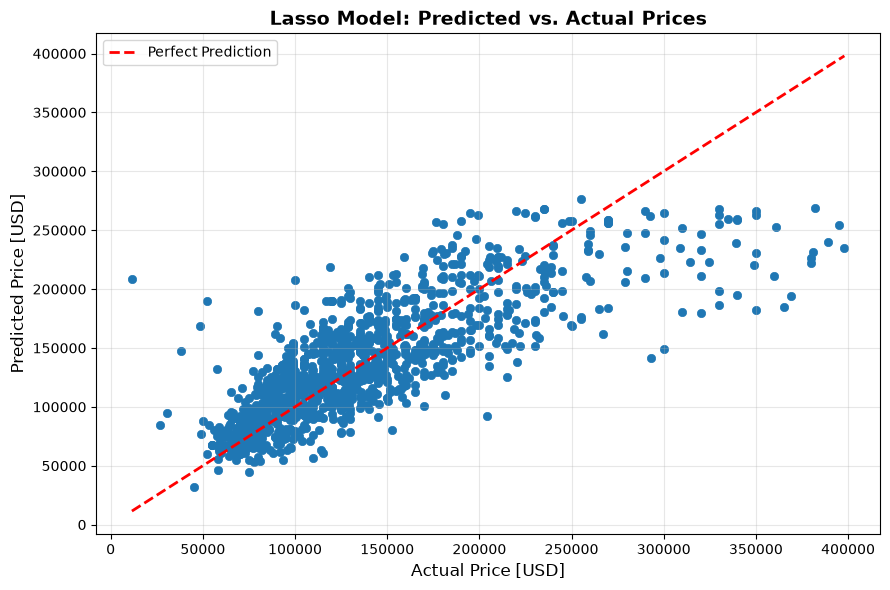

In [10]:
y_pred_lasso_4 = model_lasso_4.predict(X_test_4)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(y_test_4, y_pred_lasso_4, linewidth=0.5)

ideal_line = np.linspace(y_test_4.min(), y_test_4.max(), 100)
ax.plot(ideal_line, ideal_line, color="red", linestyle="--", linewidth=2, label="Perfect Prediction")

ax.set_xlabel("Actual Price [USD]", fontsize=12)
ax.set_ylabel("Predicted Price [USD]", fontsize=12)
ax.set_title("Lasso Model: Predicted vs. Actual Prices", fontsize=14, fontweight="bold")
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("../reports/figures/lasso_predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.2 Residual analysis (Lasso)

Residuals are actual minus predicted. A flat, even band around zero would mean errors are the same size at every price level; a funnel means they are not.

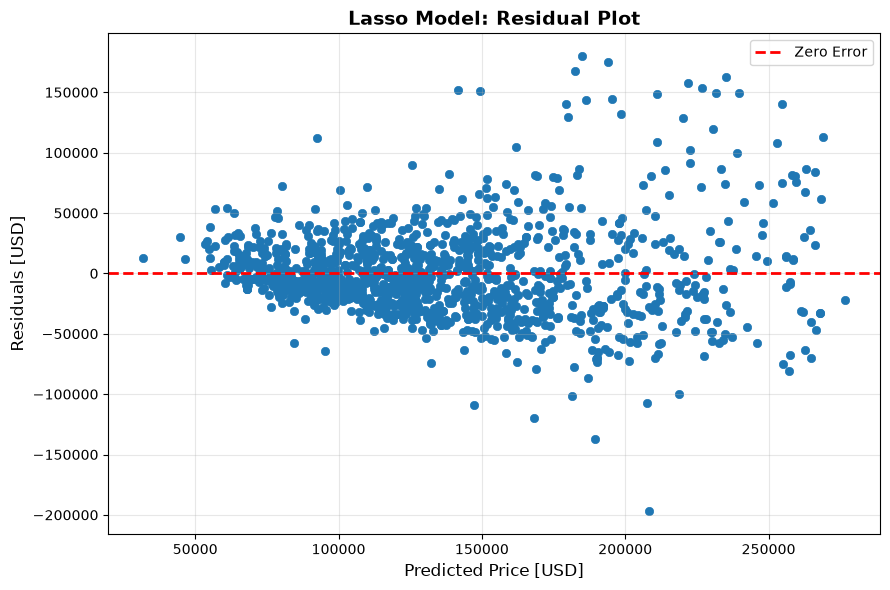

Residual mean: $-429   std: $36,929
                  count      std
(0, 100000]         326  19272.0
(100000, 150000]    500  27746.0
(150000, 200000]    275  47412.0
(200000, 300000]    149  61816.0


In [11]:
residuals_4 = y_test_4 - y_pred_lasso_4

fig_res, ax_res = plt.subplots(figsize=(9, 6))
ax_res.scatter(y_pred_lasso_4, residuals_4, linewidth=0.5)
ax_res.axhline(y=0, color="r", linestyle="--", linewidth=2, label="Zero Error")
ax_res.set_xlabel("Predicted Price [USD]", fontsize=12)
ax_res.set_ylabel("Residuals [USD]", fontsize=12)
ax_res.set_title("Lasso Model: Residual Plot", fontsize=14, fontweight="bold")
ax_res.legend(fontsize=10)
ax_res.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Error spread by predicted-price band
bands = pd.cut(
    pd.Series(np.asarray(y_pred_lasso_4), index=residuals_4.index),
    bins=[0, 100_000, 150_000, 200_000, 300_000]
)
print(f"Residual mean: ${residuals_4.mean():,.0f}   std: ${residuals_4.std():,.0f}")
print(residuals_4.groupby(bands, observed=True).agg(["count", "std"]).round(0))

### Results: predicted vs. actual and residuals (Lasso)

- Residuals average -$429 with a standard deviation of $36,929, so the model is unbiased on average: it is not systematically over- or under-predicting overall.
- The error is **not constant across price levels (heteroscedasticity)**. Residual standard deviation by predicted-price band:

| Predicted price | Listings | Residual std |
|---|---|---|
| up to $100k | 326 | $19,272 |
| $100k-$150k | 500 | $27,746 |
| $150k-$200k | 275 | $47,412 |
| $200k-$300k | 149 | $61,816 |

- Error spread in the top band is about 3.2x that of the bottom band. The residual plot forms a funnel: tight below about $150k predicted, then widening to roughly +/-$150k at the top end. The largest errors are about -$197k and +$180k.
- Above about $175k predicted, the large errors lean positive: the model tends to under-price expensive listings. Our features (size, location, neighborhood) do not capture what drives luxury prices, such as building quality, amenities and views.
- **Implication:** the headline RMSE ($36,916) overstates accuracy for cheaper apartments (typical error about $19k below $100k) and understates it for expensive ones (about $62k above $200k). The model is most reliable for typical mid-priced apartments.
- **Possible fixes (not done in this project):** log-transform the target so errors scale with price, or use a non-linear model.

## 6. Feature importance: the Lasso advantage

Lasso sets some coefficients exactly to zero, which makes it a built-in feature selector. Because we used `category_encoders`, every neighborhood column has a readable name (`neighborhood_Palermo`) rather than `x0_1`.

Note: the pipeline standardizes features before fitting, so these coefficients are in dollars **per one standard deviation** of each feature. They are good for ranking importance, but not yet in dollars per m² or dollars per neighborhood.

In [12]:
coefs_4 = model_lasso_4.named_steps["lassocv"].coef_
feature_names_4 = model_lasso_4.named_steps["onehotencoder"].get_feature_names_out()

feat_imp_4 = pd.Series(coefs_4, index=feature_names_4)

print(f"Total features: {len(feat_imp_4)}")
print(f"Non-zero features: {(feat_imp_4 != 0).sum()}")
print("\nTop 5 positive coefficients:")
print(feat_imp_4.nlargest(5))
print("\nTop 5 negative coefficients:")
print(feat_imp_4.nsmallest(5))

Total features: 59
Non-zero features: 51

Top 5 positive coefficients:
surface_covered_in_m2         39934.005268
neighborhood_Palermo          10110.309935
neighborhood_Puerto Madero    10038.988199
lat                            8714.860407
neighborhood_Belgrano          7606.474190
dtype: float64

Top 5 negative coefficients:
neighborhood_Boca           -4704.213819
neighborhood_Balvanera      -4529.273684
neighborhood_Once           -4028.205401
neighborhood_Congreso       -2421.141689
neighborhood_Villa Lugano   -2331.973956
dtype: float64


In [13]:
zero_features_4 = (feat_imp_4 == 0).sum()
total_features_4 = len(feat_imp_4)
percent_eliminated_4 = (zero_features_4 / total_features_4) * 100

print(f"Lasso eliminated {zero_features_4} out of {total_features_4} features.")
print(f"Percentage eliminated: {percent_eliminated_4:.1f}%")
print("\nEliminated features:")
print(feat_imp_4[feat_imp_4 == 0].index.tolist())

Lasso eliminated 8 out of 59 features.
Percentage eliminated: 13.6%

Eliminated features:
['neighborhood_Saavedra', 'neighborhood_Villa del Parque', 'neighborhood_Abasto', 'neighborhood_Villa General Mitre', 'neighborhood_Villa Real', 'neighborhood_Parque Avellaneda', 'neighborhood_Chacarita', 'neighborhood_']


### 6.2 Sparsity

Lasso set 8 of 59 coefficients (13.6%) exactly to zero, keeping 51. All eight are neighborhood indicators: Abasto, Saavedra, Villa del Parque, Villa Real, Villa General Mitre, Chacarita, Parque Avellaneda and the blank-name category. These are mostly neighborhoods with few training listings, where the data cannot support a reliable separate price effect once surface, latitude and longitude are accounted for.

Surface area, latitude and longitude are never eliminated. Only the sparse neighborhood indicators are.

**Caveat on reading the coefficients:** the pipeline standardizes every feature, so the raw coefficients are dollars per one standard deviation. A rare neighborhood has a very small standard deviation, so its coefficient looks small even when its dollar effect is large. For effects in real dollars, the coefficients are divided by each feature's scale (below).

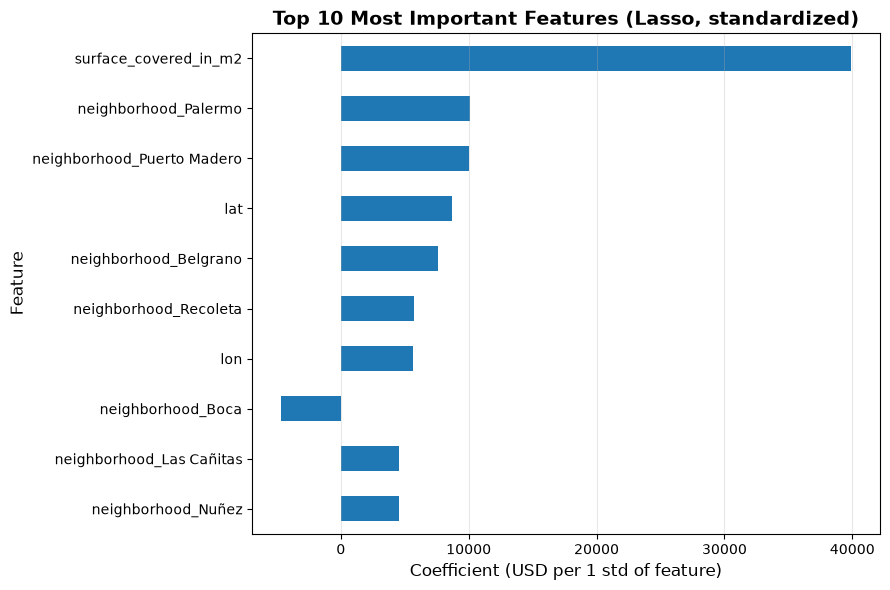

In [14]:
fig_feat, ax_feat = plt.subplots(figsize=(9, 6))
feat_imp_4.sort_values(key=abs).tail(10).plot(kind="barh", ax=ax_feat)
ax_feat.set_title("Top 10 Most Important Features (Lasso, standardized)", fontsize=14, fontweight="bold")
ax_feat.set_xlabel("Coefficient (USD per 1 std of feature)", fontsize=12)
ax_feat.set_ylabel("Feature", fontsize=12)
ax_feat.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
scaler_4 = model_lasso_4.named_steps["standardscaler"]
coef_usd_4 = pd.Series(coefs_4 / scaler_4.scale_, index=feature_names_4)

# How many training listings back each feature
X_train_enc_4 = model_lasso_4.named_steps["onehotencoder"].transform(X_train_4)
n_train_4 = X_train_enc_4.sum()   # for dummies = listings; ignore for numeric features

summary_4 = pd.DataFrame({
    "coef_std": feat_imp_4,
    "effect_usd": coef_usd_4,
    "train_listings": n_train_4.where(X_train_enc_4.nunique() == 2),
})

print("Surface effect: $%.2f per m2" % coef_usd_4["surface_covered_in_m2"])
print("\nLargest neighborhood effects in dollars:")
nb = summary_4[summary_4.index.str.startswith("neighborhood_") & (summary_4.coef_std != 0)]
print(nb.reindex(nb.effect_usd.abs().sort_values(ascending=False).index).head(10).round(0))

Surface effect: $2218.97 per m2

Largest neighborhood effects in dollars:
                            coef_std  effect_usd  train_listings
neighborhood_Puerto Madero   10039.0    114081.0            39.0
neighborhood_Las Cañitas      4559.0     70468.0            21.0
neighborhood_Villa Soldati   -1319.0    -46624.0             4.0
neighborhood_Villa Lugano    -2332.0    -40049.0            17.0
neighborhood_Boca            -4704.0    -39208.0            73.0
neighborhood_Recoleta         5690.0     38607.0           111.0
neighborhood_Once            -4028.0    -35284.0            66.0
neighborhood_Palermo         10110.0     33873.0           494.0
neighborhood_Pompeya          -848.0    -29993.0             4.0
neighborhood_Belgrano         7606.0     27038.0           433.0


### 6.3 Feature importance in dollars

The bar chart shows standardized coefficients, which rank features by importance but distort rare neighborhoods: Palermo (+$10,110) and Puerto Madero (+$10,039) look equal, yet their dollar effects differ by more than 3x. Dividing each coefficient by its feature's scale gives effects in real dollars.

- **Surface area dominates:** about **$2,219 per additional m²**, holding location constant (the single-feature model in 2.2 gave $2,275). In standardized terms it is about 4x larger than any other feature.
- **Well-supported neighborhood effects** (on top of surface, lat and lon), with at least 66 training listings each:

| Neighborhood | Effect | Train listings |
|---|---|---|
| Recoleta | +$38,607 | 111 |
| Palermo | +$33,873 | 494 |
| Belgrano | +$27,038 | 433 |
| Boca | -$39,208 | 73 |
| Once | -$35,284 | 66 |

- **Thin neighborhoods, interpret with caution:** Puerto Madero (+$114,081, 39 listings) and Las Cañitas (+$70,468, 21 listings) are plausible luxury premiums but rest on few listings, so the exact size is uncertain. Villa Soldati (-$46,624) and Pompeya (-$29,993) have only 4 training listings each, and Villa Lugano (-$40,049) has 17. Lasso kept these non-zero, but with so few listings they are most likely noise and should not be read as real price effects.
- **Takeaway:** a large coefficient only means something if enough listings support it. Counting training listings per neighborhood is the quick check for whether a coefficient reflects a real premium or small-sample noise.

### 6.4 The dominant feature

The strongest single signal in the model, by largest positive coefficient and by largest absolute coefficient.

In [16]:
top_feature_4 = feat_imp_4.idxmax()
top_coefficient_4 = feat_imp_4.max()

print(f"The most influential positive feature is: {top_feature_4}")
print(f"Its standardized coefficient is: ${top_coefficient_4:,.2f}")

top_abs_feature_4 = feat_imp_4.abs().idxmax()
print(f"\nLargest by absolute value: {top_abs_feature_4} ({feat_imp_4[top_abs_feature_4]:,.2f})")
print(f"Dollar effect: ${coef_usd_4[top_feature_4]:,.2f} per unit (m2)")

The most influential positive feature is: surface_covered_in_m2
Its standardized coefficient is: $39,934.01

Largest by absolute value: surface_covered_in_m2 (39,934.01)
Dollar effect: $2,218.97 per unit (m2)


### 6.5 Does the dominant feature make sense?

Yes. Surface area is the strongest predictor in both standardized terms ($39,934 per std) and dollars (about $2,219 per additional m²). Apartment size driving price is exactly what we would expect, and the 2.2 single-feature model found almost the same slope ($2,275 per m²). The model is not leaning on a rare neighborhood with few listings: the neighborhood effects with the biggest dollar values (Puerto Madero, Las Cañitas) are the ones with the fewest training listings (39 and 21), and they rank below surface, latitude and the large-sample neighborhoods in the standardized view.

## 7. Final model recommendation

In [17]:
best_model = df_results_4["Test_RMSE"].idxmin()

spread = df_results_4.loc[["Linear Regression", "Ridge (CV-tuned)", "Lasso (CV-tuned)"], "Test_RMSE"]
spread_usd = spread.max() - spread.min()
spread_pct = spread_usd / spread.max() * 100
improve_pct = (rmse_base_test - rmse_lasso_test) / rmse_base_test * 100
rel_err_pct = rmse_lasso_test / y_mean_4 * 100

recommendation = f"""
=================================================================
FINAL MODEL SELECTION REPORT
=================================================================

EXECUTIVE SUMMARY:
I recommend the Lasso (alpha={alpha_lasso_chosen:.0f}) model. It has the lowest
test RMSE ({best_model}), but the three predictive models are practically tied,
so the choice rests mainly on interpretability and simplicity.

PERFORMANCE COMPARISON (test RMSE):
- Baseline:           ${rmse_base_test:,.2f}
- Linear Regression:  ${rmse_linear_test:,.2f}
- Ridge (CV-tuned):   ${rmse_ridge_test:,.2f}
- Lasso (CV-tuned):   ${rmse_lasso_test:,.2f}

Lasso cuts test RMSE by {improve_pct:.1f}% versus the baseline. The three
predictive models differ by only ${spread_usd:,.0f} ({spread_pct:.2f}%), which
is well within the noise of a single fixed train-test split.

GENERALIZATION ANALYSIS:
All three models show a similar gap between test and train RMSE
(about 11%), so regularization did not change overfitting here. The
limit is the model form (linear, few features), not variance.

INTERPRETABILITY:
Lasso eliminated {zero_features_4} out of {total_features_4} features
({percent_eliminated_4:.1f}%), all of them sparse neighborhoods.

KEY PREDICTORS:
The most influential feature is {top_feature_4}
(about ${coef_usd_4[top_feature_4]:,.0f} per additional m2).

RECOMMENDATION:
I recommend deploying the Lasso model because:
1. Test RMSE is the lowest of all models (${rmse_lasso_test:,.0f}), but only
   marginally, so this alone does not justify the choice.
2. Its generalization gap is the smallest of the three (about 11.2%),
   again by a very small margin.
3. It is the simplest to explain and audit: it drops {zero_features_4} neighborhood
   indicators that the data cannot support, and its coefficients show
   which features matter.

KNOWN LIMITATIONS (must accompany any deployment):
- Typical error is about {rel_err_pct:.0f}% of the mean price (RMSE / mean).
- Errors grow with price (heteroscedasticity): residual std is about $19k
  below $100k predicted but about $62k above $200k. The headline RMSE
  overstates accuracy for expensive listings.
- Scope: mid-size apartments (31-100 m2), mostly under about $400k.
- Thin neighborhoods (Puerto Madero, Las Cañitas, Villa Soldati, Pompeya)
  have coefficients based on very few listings.
- Evaluated on a single fixed split; no repeated-split uncertainty.

=================================================================
"""

print(recommendation)


FINAL MODEL SELECTION REPORT

EXECUTIVE SUMMARY:
I recommend the Lasso (alpha=100) model. It has the lowest
test RMSE (Lasso (CV-tuned)), but the three predictive models are practically tied,
so the choice rests mainly on interpretability and simplicity.

PERFORMANCE COMPARISON (test RMSE):
- Baseline:           $61,059.08
- Linear Regression:  $36,971.86
- Ridge (CV-tuned):   $36,948.50
- Lasso (CV-tuned):   $36,916.38

Lasso cuts test RMSE by 39.5% versus the baseline. The three
predictive models differ by only $55 (0.15%), which
is well within the noise of a single fixed train-test split.

GENERALIZATION ANALYSIS:
All three models show a similar gap between test and train RMSE
(about 11%), so regularization did not change overfitting here. The
limit is the model form (linear, few features), not variance.

INTERPRETABILITY:
Lasso eliminated 8 out of 59 features
(13.6%), all of them sparse neighborhoods.

KEY PREDICTORS:
The most influential feature is surface_covered_in_m2
(about $2

### Final recommendation

**Chosen model: Lasso regression (alpha = 100, selected by cross-validation).**

- **Performance:** test RMSE of $36,916, a 39.5% reduction versus the mean baseline ($61,059). Linear Regression ($36,972) and Ridge ($36,949) are within $55 (0.15%), a difference too small to rely on from a single fixed split. Lasso is chosen mainly on secondary criteria, not on RMSE.
- **Generalization:** train-test gap of about 11% for all three models, so regularization did not change overfitting. The limit is the linear form and the small feature set (bias), not variance.
- **Interpretability:** Lasso dropped 8 of 59 features (all sparse neighborhoods), and surface area is the dominant predictor (about $2,219 per m²), which matches intuition.
- **Limitations to communicate:** typical error is about 28% of the mean price; errors grow with price (residual std about $19k below $100k predicted vs. about $62k above $200k); scope is mid-size apartments (31-100 m²); coefficients for thin neighborhoods (Puerto Madero, Las Cañitas, Villa Soldati, Pompeya) rest on very few listings; evaluation uses one fixed split.
- **Next steps:** log-transform the target to reduce the funnel, add a percentage-error metric, evaluate with repeated splits or cross-validation, and try non-linear models.